# Loan Default Prediction


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from scipy.stats import chi2_contingency

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold, cross_val_score,
    RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy import stats

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42 


## 1. Load the data

In [2]:
import pandas as pd
import numpy as np

data_path = "/Users/ghazal/Desktop/PADR/data/Training_Data.csv"


df = pd.read_csv(data_path)

if "Id" in df.columns and "ID" not in df.columns:
    df.rename(columns={"Id": "ID"}, inplace=True)

print(df.shape)
df.head()

(252000, 13)


,ID,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
0,1,1303834,23,3,single,rented,no,Mechanical_engineer,Rewa,Madhya_Pradesh,3,13,0
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
2,3,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0
3,4,6256451,41,2,single,rented,yes,Software_Developer,Bhubaneswar,Odisha,2,12,1
4,5,5768871,47,11,single,rented,no,Civil_servant,Tiruchirappalli[10],Tamil_Nadu,3,14,1


## 2. Data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 252000 entries, 0 to 251999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   ID                 252000 non-null  int64
 1   Income             252000 non-null  int64
 2   Age                252000 non-null  int64
 3   Experience         252000 non-null  int64
 4   Married/Single     252000 non-null  str  
 5   House_Ownership    252000 non-null  str  
 6   Car_Ownership      252000 non-null  str  
 7   Profession         252000 non-null  str  
 8   CITY               252000 non-null  str  
 9   STATE              252000 non-null  str  
 10  CURRENT_JOB_YRS    252000 non-null  int64
 11  CURRENT_HOUSE_YRS  252000 non-null  int64
 12  Risk_Flag          252000 non-null  int64
dtypes: int64(7), str(6)
memory usage: 25.0 MB


In [4]:
df.describe(exclude=[np.number])

,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE
count,252000,252000,252000,252000,252000,252000
unique,2,3,2,51,317,29
top,single,rented,no,Physician,Vijayanagaram,Uttar_Pradesh
freq,226272,231898,176000,5957,1259,28400


In [5]:
df.describe(include=[np.number])

,ID,Income,Age,Experience,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
count,252000.000000,2.520000e+05,252000.000000,252000.000000,252000.000000,252000.000000,252000.000000
mean,126000.500000,4.997117e+06,49.954071,10.084437,6.333877,11.997794,0.123000
std,72746.278255,2.878311e+06,17.063855,6.002590,3.647053,1.399037,0.328438
min,1.000000,1.031000e+04,21.000000,0.000000,0.000000,10.000000,0.000000
25%,63000.750000,2.503015e+06,35.000000,5.000000,3.000000,11.000000,0.000000
50%,126000.500000,5.000694e+06,50.000000,10.000000,6.000000,12.000000,0.000000
75%,189000.250000,7.477502e+06,65.000000,15.000000,9.000000,13.000000,0.000000
max,252000.000000,9.999938e+06,79.000000,20.000000,14.000000,14.000000,1.000000


In [6]:
print("missing values per column:")
print(df.isnull().sum())
print("\nduplicate rows:", df.duplicated().sum())

missing values per column:
ID                   0
Income               0
Age                  0
Experience           0
Married/Single       0
House_Ownership      0
Car_Ownership        0
Profession           0
CITY                 0
STATE                0
CURRENT_JOB_YRS      0
CURRENT_HOUSE_YRS    0
Risk_Flag            0
dtype: int64

duplicate rows: 0


In [7]:
target_col = "Risk_Flag"

counts = df[target_col].value_counts()
ratio = counts[0] / counts[1]
print(counts)
print(f"\nclass balance: {counts[1] / counts.sum():.1%} defaulters, "
      f"{counts[0] / counts.sum():.1%} non-defaulters")
print(f"imbalance ratio (majority:minority) ~= {ratio:.1f} : 1")
print(f"a classifier that always predicts 'no default' would score "
      f"{counts[0] / counts.sum():.1%} accuracy while catching ZERO defaulters "
      f"- this is why accuracy alone is not the metric to optimize here.")


Risk_Flag
0    221004
1     30996
Name: count, dtype: int64

class balance: 12.3% defaulters, 87.7% non-defaulters
imbalance ratio (majority:minority) ~= 7.1 : 1
a classifier that always predicts 'no default' would score 87.7% accuracy while catching ZERO defaulters - this is why accuracy alone is not the metric to optimize here.


<Axes: xlabel='Risk_Flag', ylabel='count'>

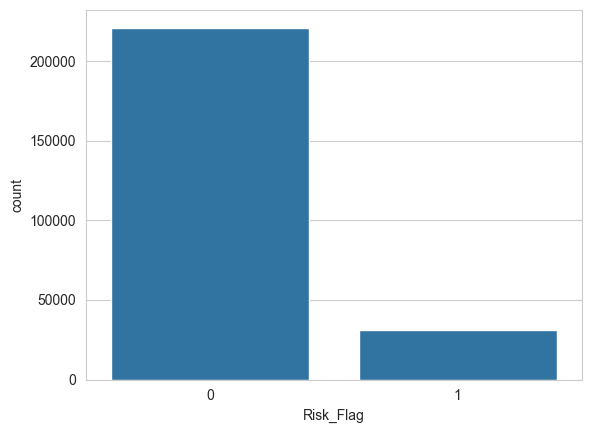

In [8]:
sns.countplot(data=df, x='Risk_Flag')

In [9]:
pd.set_option("display.float_format", "{:,.2f}".format)
df.groupby("Profession")["Income"].agg(["min", "max", "mean"]).sort_values(by="max", ascending=False).T

Profession,Police_officer,Librarian,Drafter,Aviator,Secretary,Designer,Statistician,Computer_hardware_engineer,Surgeon,Biomedical_Engineer,Economist,Surveyor,Politician,Computer_operator,Analyst,Engineer,Chartered_Accountant,Official,Hotel_Manager,Civil_engineer,Geologist,Financial_Analyst,Mechanical_engineer,Fashion_Designer,Dentist,...,Physician,Psychologist,Comedian,Chemical_engineer,Technology_specialist,Architect,Civil_servant,Technician,Magistrate,Firefighter,Technical_writer,Web_designer,Air_traffic_controller,Flight_attendant,Chef,Artist,Lawyer,Scientist,Graphic_Designer,Petroleum_Engineer,Consultant,Army_officer,Software_Developer,Design_Engineer,Microbiologist
min,"13,220.00","25,331.00","14,936.00","53,134.00","72,334.00","12,841.00","31,705.00","13,357.00","18,215.00","19,472.00","16,890.00","11,114.00","16,909.00","28,070.00","11,550.00","10,310.00","15,613.00","13,629.00","17,801.00","25,674.00","34,955.00","17,660.00","37,057.00","12,766.00","26,499.00",...,"12,608.00","33,224.00","13,429.00","26,926.00","17,496.00","11,854.00","11,430.00","16,045.00","16,212.00","29,380.00","11,799.00","21,799.00","14,339.00","11,695.00","11,735.00","31,297.00","28,993.00","13,792.00","10,675.00","22,921.00","25,161.00","12,902.00","51,528.00","44,761.00","12,825.00"
max,"9,999,938.00","9,999,400.00","9,999,180.00","9,998,280.00","9,998,070.00","9,996,946.00","9,996,861.00","9,996,192.00","9,995,445.00","9,994,932.00","9,994,882.00","9,994,518.00","9,994,061.00","9,993,961.00","9,993,798.00","9,993,649.00","9,993,403.00","9,993,041.00","9,992,692.00","9,992,141.00","9,991,298.00","9,990,776.00","9,990,505.00","9,990,182.00","9,989,145.00",...,"9,987,805.00","9,985,964.00","9,984,983.00","9,984,718.00","9,984,686.00","9,984,145.00","9,983,131.00","9,982,680.00","9,982,430.00","9,980,725.00","9,980,565.00","9,980,350.00","9,979,373.00","9,979,070.00","9,977,117.00","9,976,619.00","9,976,302.00","9,975,985.00","9,973,420.00","9,968,353.00","9,967,854.00","9,967,074.00","9,964,816.00","9,962,923.00","9,962,662.00"
mean,"4,502,915.76","5,007,589.70","4,654,804.63","5,074,103.52","5,102,879.89","5,336,802.23","5,028,648.27","4,989,531.17","5,235,358.71","4,982,527.56","4,916,001.92","5,112,352.28","4,913,567.98","5,112,549.85","4,894,181.21","4,814,755.19","5,002,232.42","4,737,617.36","4,996,878.34","4,755,441.02","4,879,361.63","5,145,752.51","5,175,032.07","5,070,883.08","4,948,818.69",...,"4,780,383.77","5,357,795.26","5,199,538.53","5,189,804.99","4,985,643.17","5,004,078.75","4,947,842.64","4,971,491.56","4,769,919.82","5,046,134.01","4,922,265.75","4,893,094.55","4,958,421.71","4,592,177.01","4,839,915.14","5,164,765.18","5,128,131.46","5,282,710.42","4,900,447.05","5,443,309.83","5,138,435.81","5,094,472.73","4,891,296.09","4,840,220.61","5,035,358.00"


## 3. Exploratory Data Analysis

In [ ]:
result = df.groupby("STATE").Risk_Flag.apply(lambda x: (x.sum() / x.size) * 100) \
           .sort_values(ascending=False)

display(result.to_frame().T)  
display(result.head(5).to_frame().T)  


STATE,Manipur,Tripura,Kerala,Jammu_and_Kashmir,Madhya_Pradesh,Odisha,Rajasthan,Jharkhand,Chhattisgarh,Himachal_Pradesh,Assam,Bihar,Uttar_Pradesh[5],Telangana,West_Bengal,Haryana,Gujarat,Uttar_Pradesh,Puducherry,Andhra_Pradesh,Maharashtra,Mizoram,Delhi,Tamil_Nadu,Karnataka,Chandigarh,Punjab,Uttarakhand,Sikkim
Risk_Flag,21.55,16.81,16.71,15.90,15.44,14.26,14.08,13.33,13.33,13.33,13.17,13.06,13.06,13.01,12.81,12.42,11.77,11.77,11.65,11.60,11.33,11.07,10.46,10.32,10.03,9.30,9.00,7.10,4.61


STATE,Manipur,Tripura,Kerala,Jammu_and_Kashmir,Madhya_Pradesh
Risk_Flag,21.55,16.81,16.71,15.90,15.44


In [11]:
df.groupby("Married/Single").Risk_Flag.apply(lambda x: (x.sum() / x.size) * 100).sort_values(ascending=False).to_frame().T

Married/Single,single,married
Risk_Flag,12.53,10.25


<Axes: xlabel='Car_Ownership', ylabel='count'>

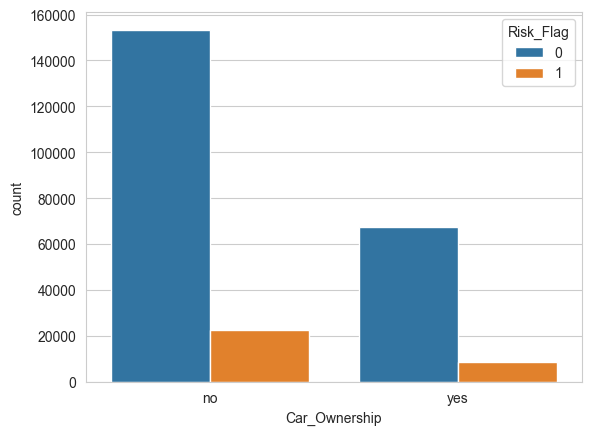

In [12]:
df.groupby("Car_Ownership").Risk_Flag.apply(lambda x: (x.sum() / x.size) * 100).sort_values(ascending=False).to_frame().T
sns.countplot(x='Car_Ownership', hue='Risk_Flag', data=df)

<Axes: xlabel='House_Ownership', ylabel='count'>

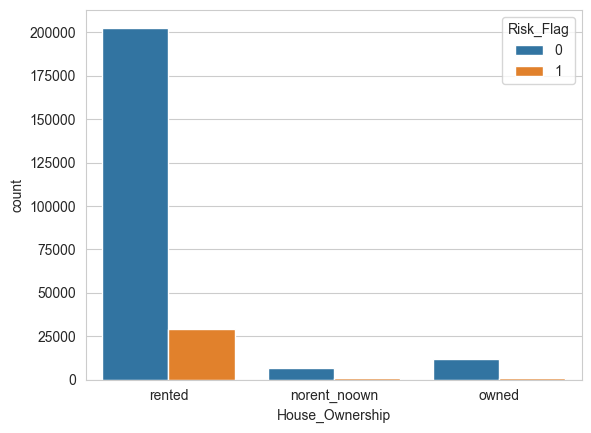

In [13]:
sns.countplot(x='House_Ownership', hue='Risk_Flag', data=df)


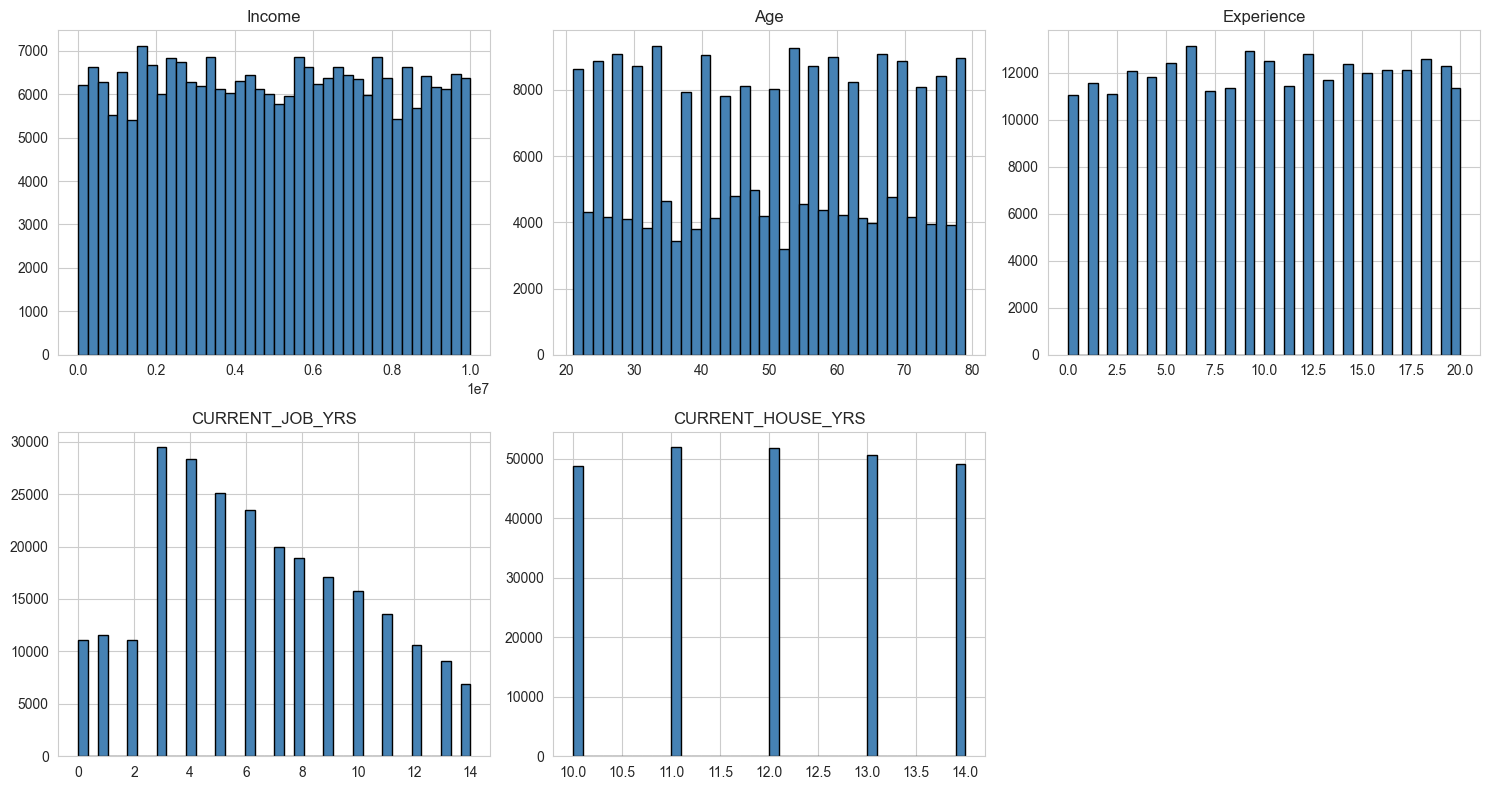

In [14]:
num_cols = ["Income", "Age", "Experience", "CURRENT_JOB_YRS", "CURRENT_HOUSE_YRS"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=40, color="steelblue", edgecolor="black")
    axes[i].set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

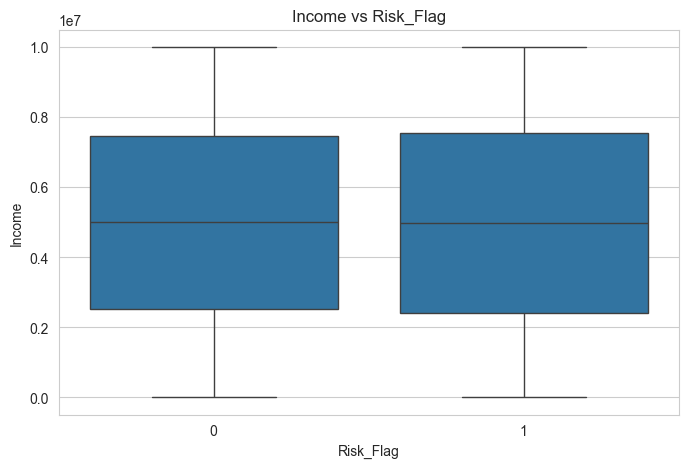

In [15]:
# how does income look for defaulters vs non-defaulters
plt.figure(figsize=(8, 5))
sns.boxplot(x=target_col, y="Income", data=df)
plt.title("Income vs Risk_Flag")
plt.show()

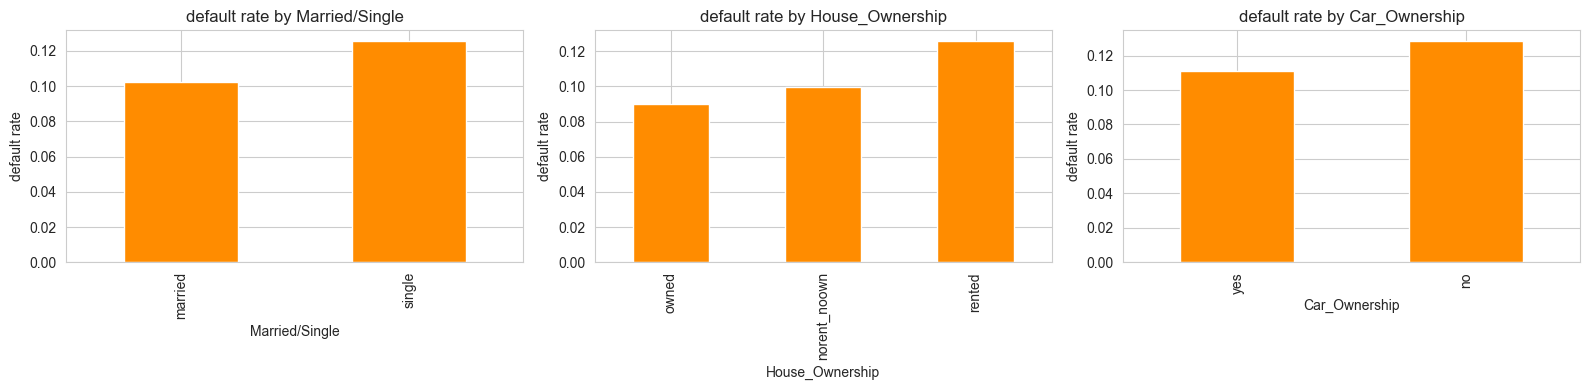

In [16]:
cat_cols = ["Married/Single", "House_Ownership", "Car_Ownership"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(cat_cols):
    rate = df.groupby(col)[target_col].mean().sort_values()
    rate.plot(kind="bar", ax=axes[i], color="darkorange")
    axes[i].set_title(f"default rate by {col}")
    axes[i].set_ylabel("default rate")
plt.tight_layout()
plt.show()

In [71]:
result = df.groupby("Profession").Risk_Flag.apply(lambda x: (x.sum() / x.size) * 100) \
             .sort_values(ascending=False)

display(result.to_frame(name="Risk %"))   
display(result.head(5).to_frame(name="Risk %"))  # Top 5

,Risk %
Profession,
Police_officer,16.41
Chartered_Accountant,15.36
Army_officer,15.21
Surveyor,15.15
Software_Developer,14.84
Scientist,14.43
Geologist,14.43
Civil_engineer,13.58
Official,13.58


,Risk %
Profession,
Police_officer,16.41
Chartered_Accountant,15.36
Army_officer,15.21
Surveyor,15.15
Software_Developer,14.84


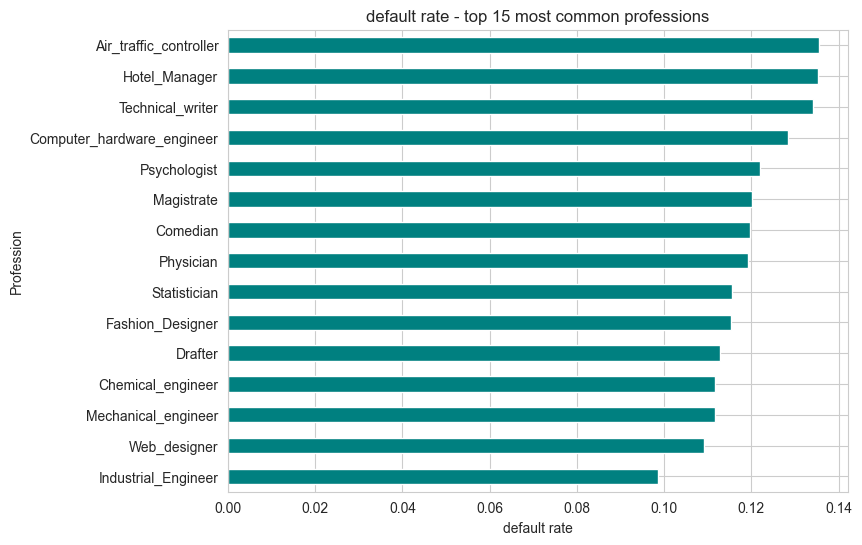

In [ ]:
top_professions = df["Profession"].value_counts().head(15).index
prof_rate = df[df["Profession"].isin(top_professions)].groupby("Profession")[target_col].mean().sort_values()

plt.figure(figsize=(8, 6))
prof_rate.plot(kind="barh", color="teal")
plt.title("default rate - top 15 most common professions")
plt.xlabel("default rate")
plt.show()

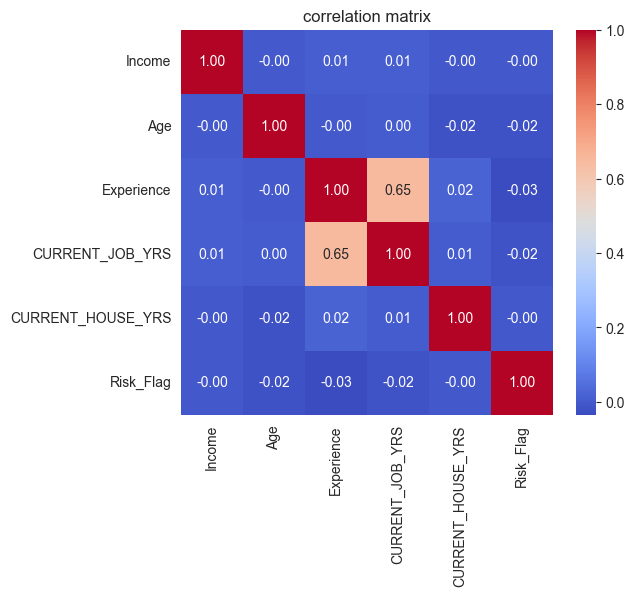

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols + [target_col]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("correlation matrix")
plt.show()

In [57]:
def pearson_correlation(x, y, title):
    corr, p = pearsonr(x, y)

    print("="*50)
    print(title)
    print(f"Pearson Correlation : {corr:.4f}")
    print(f"P-value             : {p:.6f}")



In [58]:
pearson_correlation(df["Income"], df["Risk_Flag"], "Income & Risk Flag Correlation")

Income & Risk Flag Correlation
Pearson Correlation : -0.0031
P-value             : 0.120722


In [59]:
pearson_correlation(df["Age"], df["Risk_Flag"], "Age & Risk Flag Correlation")

Age & Risk Flag Correlation
Pearson Correlation : -0.0218
P-value             : 0.000000


In [60]:
pearson_correlation(df["Experience"], df["Risk_Flag"], "Experience & Risk Flag Correlation")

Experience & Risk Flag Correlation
Pearson Correlation : -0.0345
P-value             : 0.000000


In [62]:
pearson_correlation(df["CURRENT_JOB_YRS"], df["Risk_Flag"], "Current Job Years & Risk Flag Correlation")

Current Job Years & Risk Flag Correlation
Pearson Correlation : -0.0169
P-value             : 0.000000


In [ ]:


table = pd.crosstab(df["Car_Ownership"], df["Risk_Flag"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 145.42374419378916
P-value: 1.7350853850183742e-33


## 4. Feature Engineering


In [ ]:
def engineer_features(df):
    df = df.copy()

    
    df["job_stability_ratio"] = (
        df["CURRENT_JOB_YRS"] /
        df["Experience"].replace(0, 1)
    )

    
    df["house_stability_ratio"] = (
        df["CURRENT_HOUSE_YRS"] /
        df["Experience"].replace(0, 1)
    )

    
    df["income_per_exp_year"] = (
        df["Income"] /
        (df["Experience"] + 1)
    )

    
    df["age_bucket"] = pd.cut(
        df["Age"],
        bins=[0, 25, 35, 45, 55, 100],
        labels=["<25", "25-35", "35-45", "45-55", "55+"]
    )

    return df

df = engineer_features(df)

df[[
    "job_stability_ratio",
    "house_stability_ratio",
    "income_per_exp_year",
    "age_bucket"
]].head()

,job_stability_ratio,house_stability_ratio,income_per_exp_year,age_bucket
0,1.00,4.33,"325,958.50",<25
1,0.90,1.30,"688,592.36",35-45
2,1.00,2.50,"798,363.00",55+
3,1.00,6.00,"2,085,483.67",35-45
4,0.27,1.27,"480,739.25",45-55


## 5. Preprocessing (encoding categoricals)

In [20]:
target_col = "Risk_Flag"

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df[target_col],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df[target_col],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(176400, 17)
(37800, 17)
(37800, 17)


In [21]:
high_card_cols = ["CITY", "STATE", "Profession"]
low_card_cols = ["Married/Single", "House_Ownership", "Car_Ownership", "age_bucket"]

for col in train_df[high_card_cols]:
    print(col, train_df[col].nunique())

CITY 317
STATE 29
Profession 51


### Encoding: K-fold target encoding 



In [22]:
def kfold_target_encode(train, test, col, target, n_splits=5, smoothing=10,
                         random_state=RANDOM_STATE):
    
    train = train.copy()
    test = test.copy()
    global_mean = train[target].mean()
    new_col = col + "_te"
    train[new_col] = global_mean

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    for tr_idx, val_idx in kf.split(train):
        fold_means = train.iloc[tr_idx].groupby(col)[target].mean()
        fold_counts = train.iloc[tr_idx].groupby(col)[target].count()
        smoothed = (fold_means * fold_counts + global_mean * smoothing) / (fold_counts + smoothing)
        train.iloc[val_idx, train.columns.get_loc(new_col)] = (
            train.iloc[val_idx][col].map(smoothed).fillna(global_mean)
        )

    
    full_means = train.groupby(col)[target].mean()
    full_counts = train.groupby(col)[target].count()
    full_smoothed = (full_means * full_counts + global_mean * smoothing) / (full_counts + smoothing)
    test[new_col] = test[col].map(full_smoothed).fillna(global_mean)

    return train, test


def encode_features(train, test, high_card_cols, low_card_cols, target):
    train = train.copy()
    test = test.copy()

    # high-cardinality -> out-of-fold target encoding
    for col in high_card_cols:
        train, test = kfold_target_encode(train, test, col, target)
    train = train.drop(columns=high_card_cols)
    test = test.drop(columns=high_card_cols)

    # low-cardinality -> one-hot (no ordinal relationship, few categories)
    train = pd.get_dummies(train, columns=low_card_cols, drop_first=True)
    test = pd.get_dummies(test, columns=low_card_cols, drop_first=True)

    # make sure both sets end up with the same columns
    train, test = train.align(test, join="left", axis=1, fill_value=0)
    return train, test


train_enc, val_enc = encode_features(
    train_df,
    val_df,
    high_card_cols,
    low_card_cols,
    target_col
)

_, test_enc = encode_features(
    train_df,
    test_df,
    high_card_cols,
    low_card_cols,
    target_col
)
train_enc.head()


,ID,Income,Age,Experience,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag,job_stability_ratio,house_stability_ratio,income_per_exp_year,CITY_te,STATE_te,Profession_te,Married/Single_single,House_Ownership_owned,House_Ownership_rented,Car_Ownership_yes,age_bucket_25-35,age_bucket_35-45,age_bucket_45-55,age_bucket_55+
0,203210,6840395,40,19,9,12,0,0.47,0.63,"342,019.75",0.15,0.10,0.11,True,False,True,True,False,True,False,False
1,42904,9618732,38,11,11,12,0,1.00,1.09,"801,561.00",0.10,0.13,0.14,True,False,True,True,False,True,False,False
2,59096,6861713,42,5,5,12,0,1.00,2.40,"1,143,618.83",0.14,0.12,0.12,True,False,True,False,False,True,False,False
3,69517,8454331,61,3,3,11,0,1.00,3.67,"2,113,582.75",0.12,0.12,0.13,False,False,True,False,False,False,False,True
4,232570,2937858,76,8,8,14,0,1.00,1.75,"326,428.67",0.15,0.12,0.13,False,False,True,False,False,False,False,True


In [23]:
drop_cols = ["ID", "Risk_Flag"]

feature_cols = [c for c in train_enc.columns if c not in drop_cols]

X_train = train_enc[feature_cols]
y_train = train_df[target_col].astype(int)

X_val = val_enc[feature_cols]
y_val = val_df[target_col].astype(int)

X_test = test_enc[feature_cols]
y_test = test_df[target_col].astype(int)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(176400, 19)
(37800, 19)
(37800, 19)


## 6. Fixing the class imbalance


In [ ]:
print("before resampling:", y_train.value_counts().to_dict())

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
X_train_scaled_res, y_train_scaled_res = smote.fit_resample(X_train_scaled, y_train)
print("after SMOTE:", y_train_res.value_counts().to_dict())

smote_tomek = SMOTETomek(random_state=RANDOM_STATE)
X_train_st, y_train_st = smote_tomek.fit_resample(X_train, y_train)
print("after SMOTETomek:", y_train_st.value_counts().to_dict())

undersampler = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_under, y_train_under = undersampler.fit_resample(X_train, y_train)
X_train_scaled_under, y_train_scaled_under = undersampler.fit_resample(X_train_scaled, y_train)
print("after undersampling:", y_train_under.value_counts().to_dict())


scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\nscale_pos_weight for boosting models: {scale_pos_weight:.2f}")


before resampling: {0: 154703, 1: 21697}
after SMOTE: {0: 154703, 1: 154703}
after SMOTETomek: {0: 150868, 1: 150868}
after ADASYN: {0: 154703, 1: 152099}
after undersampling: {0: 21697, 1: 21697}

scale_pos_weight for boosting models: 7.13


In [25]:
def get_scores(y_true, y_pred, y_prob):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_weighted": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "auc": roc_auc_score(y_true, y_prob),
    }


## 7. Model Development

In [26]:
model_configs = {
    "Logistic Regression (SMOTE)": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        X_train_scaled_res, y_train_scaled_res, X_val_scaled
    ),
    "Decision Tree (SMOTE)": (
        DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
        X_train_res, y_train_res, X_val
    ),
    "Random Forest (SMOTE)": (
        RandomForestClassifier(n_estimators=300, max_depth=12,
                                random_state=RANDOM_STATE, n_jobs=-1),
        X_train_res, y_train_res, X_val
    ),
    "Random Forest (SMOTETomek)": (
        RandomForestClassifier(n_estimators=300, max_depth=12,
                                random_state=RANDOM_STATE, n_jobs=-1),
        X_train_st, y_train_st, X_val
    ),
    "Logistic Regression (Undersample)": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        X_train_scaled_under, y_train_scaled_under, X_val_scaled
    ),
    "Random Forest (Undersample)": (
        RandomForestClassifier(n_estimators=300, max_depth=12,
                                random_state=RANDOM_STATE, n_jobs=-1),
        X_train_under, y_train_under, X_val
    ),
    "Random Forest (class_weight)": (
        RandomForestClassifier(n_estimators=300, max_depth=12,
                                class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1),
        X_train, y_train, X_val
    ),
    "XGBoost (scale_pos_weight)": (
        XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                       subsample=0.8, colsample_bytree=0.8,
                       scale_pos_weight=scale_pos_weight,
                       eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1),
        X_train, y_train, X_val
    ),
    "LightGBM (scale_pos_weight)": (
        LGBMClassifier(n_estimators=400, max_depth=-1, num_leaves=63,
                        learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                        scale_pos_weight=scale_pos_weight,
                        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        X_train, y_train, X_val
    ),
    "CatBoost (scale_pos_weight)": (
        CatBoostClassifier(iterations=600, depth=6, learning_rate=0.03,
                            l2_leaf_reg=5, bagging_temperature=0.5,
                            scale_pos_weight=scale_pos_weight,
                            random_state=RANDOM_STATE, verbose=False),
        X_train, y_train, X_val
    ),
}

results = {}

for name, (model, Xtr, ytr, Xv) in model_configs.items():
    model.fit(Xtr, ytr)
    val_probs = model.predict_proba(Xv)[:, 1]
    val_preds = (val_probs >= 0.5).astype(int)

    scores = get_scores(y_val, val_preds, val_probs)
    results[name] = {"model": model, "X_val": Xv, "probs": val_probs, "preds": val_preds, **scores}

    print(f"{name:32s}: acc={scores['accuracy']:.3f}  "
          f"prec={scores['precision']:.3f}  rec={scores['recall']:.3f}  f1={scores['f1']:.3f}  "
          f"f1_macro={scores['f1_macro']:.3f}  f1_weighted={scores['f1_weighted']:.3f}  "
          f"auc={scores['auc']:.3f}")


Logistic Regression (SMOTE)     : acc=0.607  prec=0.170  rec=0.566  f1=0.262  f1_macro=0.497  f1_weighted=0.674  auc=0.626
Decision Tree (SMOTE)           : acc=0.549  prec=0.181  rec=0.758  f1=0.293  f1_macro=0.481  f1_weighted=0.623  auc=0.701
Random Forest (SMOTE)           : acc=0.726  prec=0.283  rec=0.804  f1=0.419  f1_macro=0.620  f1_weighted=0.771  auc=0.827
Random Forest (SMOTETomek)      : acc=0.730  prec=0.287  rec=0.805  f1=0.423  f1_macro=0.623  f1_weighted=0.774  auc=0.830
Logistic Regression (Undersample): acc=0.609  prec=0.171  rec=0.567  f1=0.263  f1_macro=0.498  f1_weighted=0.676  auc=0.626
Random Forest (Undersample)     : acc=0.809  prec=0.369  rec=0.782  f1=0.502  f1_macro=0.692  f1_weighted=0.835  auc=0.870
Random Forest (class_weight)    : acc=0.838  prec=0.412  rec=0.755  f1=0.533  f1_macro=0.718  f1_weighted=0.856  auc=0.866
XGBoost (scale_pos_weight)      : acc=0.838  prec=0.416  rec=0.788  f1=0.545  f1_macro=0.723  f1_weighted=0.858  auc=0.871
LightGBM (scale

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_specs = {
    "Logistic Regression (SMOTE)": ("smote", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train_scaled),
    "Decision Tree (SMOTE)": ("smote", DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE), X_train),
    "Random Forest (SMOTE)": ("smote", RandomForestClassifier(n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1), X_train),
    "Random Forest (Undersample)": ("under", RandomForestClassifier(n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1), X_train),
    "Random Forest (class_weight)": (None, RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), X_train),
    "XGBoost (scale_pos_weight)": (None, XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1), X_train),
    "LightGBM (scale_pos_weight)": (None, LGBMClassifier(n_estimators=400, num_leaves=63, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1), X_train),
}

cv_auc_results = {}  

for name, (resampler, model, Xc) in cv_specs.items():
    if resampler == "smote":
        pipe = ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])
    elif resampler == "under":
        pipe = ImbPipeline([("under", RandomUnderSampler(random_state=RANDOM_STATE)), ("model", model)])
    else:
        pipe = model
    scores = cross_val_score(pipe, Xc, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_auc_results[name] = scores.mean()
    print(f"{name:32s}: cv auc = {scores.mean():.3f} (+/- {scores.std():.3f})")


Logistic Regression (SMOTE)     : cv auc = 0.626 (+/- 0.002)
Decision Tree (SMOTE)           : cv auc = 0.699 (+/- 0.006)
Random Forest (SMOTE)           : cv auc = 0.820 (+/- 0.003)
Random Forest (Undersample)     : cv auc = 0.864 (+/- 0.002)
Random Forest (class_weight)    : cv auc = 0.864 (+/- 0.001)
XGBoost (scale_pos_weight)      : cv auc = 0.870 (+/- 0.002)
LightGBM (scale_pos_weight)     : cv auc = 0.891 (+/- 0.003)


## 8. Model Evaluation



In [28]:
for name, r in results.items():
    print(f"--- {name} ---")
    print(confusion_matrix(y_val, r["preds"]))
    print(classification_report(y_val, r["preds"]))

--- Logistic Regression (SMOTE) ---
[[20301 12849]
 [ 2017  2633]]
              precision    recall  f1-score   support

           0       0.91      0.61      0.73     33150
           1       0.17      0.57      0.26      4650

    accuracy                           0.61     37800
   macro avg       0.54      0.59      0.50     37800
weighted avg       0.82      0.61      0.67     37800

--- Decision Tree (SMOTE) ---
[[17237 15913]
 [ 1124  3526]]
              precision    recall  f1-score   support

           0       0.94      0.52      0.67     33150
           1       0.18      0.76      0.29      4650

    accuracy                           0.55     37800
   macro avg       0.56      0.64      0.48     37800
weighted avg       0.85      0.55      0.62     37800

--- Random Forest (SMOTE) ---
[[23692  9458]
 [  910  3740]]
              precision    recall  f1-score   support

           0       0.96      0.71      0.82     33150
           1       0.28      0.80      0.42     

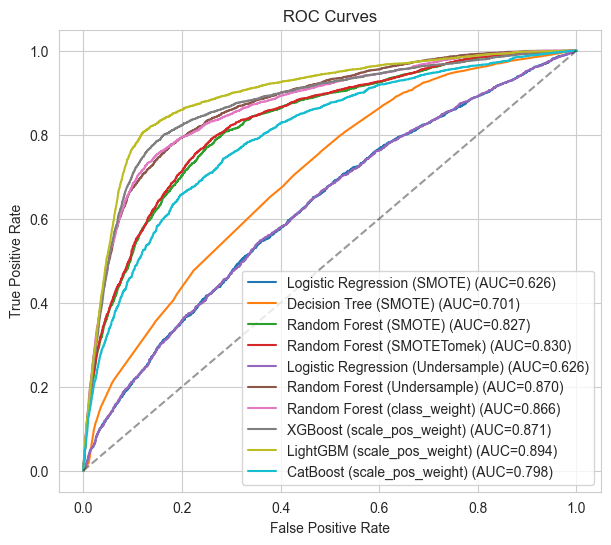

In [29]:
plt.figure(figsize=(7, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_val, r["probs"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={r['auc']:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

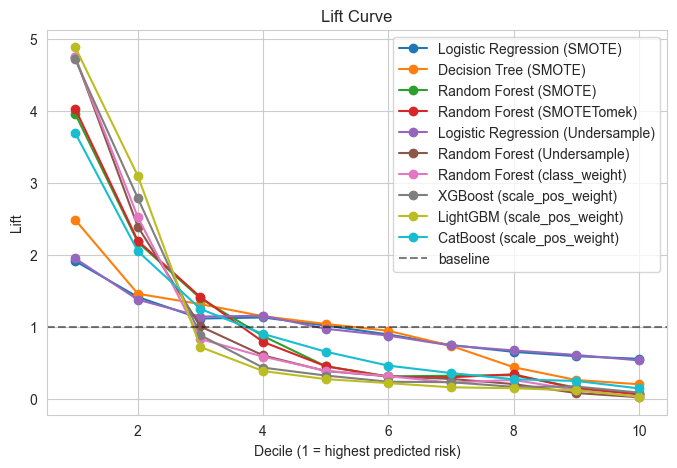

In [30]:
def lift_curve(y_true, y_prob, n_bins=10):
    
    df = pd.DataFrame({"y": y_true, "prob": y_prob})
    df["bin"] = pd.qcut(df["prob"].rank(method="first"), n_bins, labels=False)

    base_rate = df["y"].mean()
    lift = df.groupby("bin")["y"].mean().sort_index(ascending=False).reset_index(drop=True)
    lift_ratio = lift / base_rate
    lift_ratio.index = lift_ratio.index + 1  
    return lift_ratio

plt.figure(figsize=(8, 5))
for name, r in results.items():
    lift = lift_curve(y_val.values, r["probs"])
    plt.plot(lift.index, lift.values, marker="o", label=name)

plt.axhline(1.0, color="black", linestyle="--", alpha=0.5, label="baseline")
plt.xlabel("Decile (1 = highest predicted risk)")
plt.ylabel("Lift")
plt.title("Lift Curve")
plt.legend()
plt.show()

In [31]:
import numpy as np
from scipy import stats

def h_measure(y_true, y_prob, alpha=2, beta=2, n_points=1000):
    
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    n1 = (y_true == 1).sum()
    n0 = (y_true == 0).sum()

    if n1 == 0 or n0 == 0:
        raise ValueError("Both classes must be present in y_true.")

    pi1 = n1 / (n1 + n0)
    pi0 = n0 / (n1 + n0)

    order = np.argsort(-y_prob)
    y_sorted = y_true[order]

    tpr = np.concatenate(([0], np.cumsum(y_sorted == 1) / n1))
    fpr = np.concatenate(([0], np.cumsum(y_sorted == 0) / n0))

    c_grid = np.linspace(1e-3, 1 - 1e-3, n_points)
    weights = stats.beta.pdf(c_grid, alpha, beta)

    losses = np.empty_like(c_grid)
    for i, c in enumerate(c_grid):
        loss_per_threshold = c * pi1 * (1 - tpr) + (1 - c) * pi0 * fpr
        losses[i] = loss_per_threshold.min()

    trivial_loss = np.minimum(c_grid * pi1, (1 - c_grid) * pi0)

    L = np.trapezoid(losses * weights, c_grid)
    L_max = np.trapezoid(trivial_loss * weights, c_grid)

    return 1 - L / L_max


for name, r in results.items():
    h = h_measure(y_val.values, r["probs"])
    print(f"{name}: H-measure = {h:.4f}")


Logistic Regression (SMOTE): H-measure = 0.0194
Decision Tree (SMOTE): H-measure = 0.0446
Random Forest (SMOTE): H-measure = 0.1800
Random Forest (SMOTETomek): H-measure = 0.1853
Logistic Regression (Undersample): H-measure = 0.0198
Random Forest (Undersample): H-measure = 0.2672
Random Forest (class_weight): H-measure = 0.2710
XGBoost (scale_pos_weight): H-measure = 0.2792
LightGBM (scale_pos_weight): H-measure = 0.3213
CatBoost (scale_pos_weight): H-measure = 0.1466


In [32]:
summary = pd.DataFrame({
    name: {
        "Accuracy": r["accuracy"],
        "Precision": r["precision"], "Recall": r["recall"], "F1": r["f1"],
        "Precision (macro)": r["precision_macro"], "Recall (macro)": r["recall_macro"], "F1 (macro)": r["f1_macro"],
        "Precision (weighted)": r["precision_weighted"], "Recall (weighted)": r["recall_weighted"], "F1 (weighted)": r["f1_weighted"],
        "AUC": r["auc"], "H-measure": h_measure(y_val.values, r["probs"]),
    }
    for name, r in results.items()
}).T

summary.sort_values("H-measure", ascending=False)


,Accuracy,Precision,Recall,F1,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),AUC,H-measure
LightGBM (scale_pos_weight),0.87,0.49,0.80,0.61,0.73,0.84,0.77,0.91,0.87,0.89,0.89,0.32
XGBoost (scale_pos_weight),0.84,0.42,0.79,0.54,0.69,0.82,0.72,0.90,0.84,0.86,0.87,0.28
Random Forest (class_weight),0.84,0.41,0.75,0.53,0.69,0.80,0.72,0.89,0.84,0.86,0.87,0.27
Random Forest (Undersample),0.81,0.37,0.78,0.50,0.67,0.80,0.69,0.89,0.81,0.83,0.87,0.27
Random Forest (SMOTETomek),0.73,0.29,0.81,0.42,0.63,0.76,0.62,0.88,0.73,0.77,0.83,0.19
Random Forest (SMOTE),0.73,0.28,0.80,0.42,0.62,0.76,0.62,0.88,0.73,0.77,0.83,0.18
CatBoost (scale_pos_weight),0.73,0.28,0.71,0.40,0.61,0.72,0.61,0.87,0.73,0.78,0.80,0.15
Decision Tree (SMOTE),0.55,0.18,0.76,0.29,0.56,0.64,0.48,0.85,0.55,0.62,0.70,0.04
Logistic Regression (Undersample),0.61,0.17,0.57,0.26,0.54,0.59,0.50,0.82,0.61,0.68,0.63,0.02
Logistic Regression (SMOTE),0.61,0.17,0.57,0.26,0.54,0.59,0.50,0.82,0.61,0.67,0.63,0.02


## 8b. Hyperparameter Tuning


In [33]:
def normalize(s):
    s = s.astype(float)
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng > 0 else s * 0

h_norm = normalize(summary["H-measure"])
cv_series = pd.Series({name: cv_auc_results.get(name) for name in summary.index})
cv_norm = normalize(cv_series.dropna())

combined = h_norm.copy()
for name in combined.index:
    if name in cv_norm.index:
        combined[name] = 0.5 * h_norm[name] + 0.5 * cv_norm[name]

best_model_name = combined.idxmax()
print("model ranking (blended H-measure + CV AUC, higher is better):")
print(combined.sort_values(ascending=False))
print("\ntuning:", best_model_name)

tuning_configs = {
    "XGBoost (scale_pos_weight)": (
        XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric="auc",
                       random_state=RANDOM_STATE, n_jobs=-1),
        {
            "n_estimators": [200, 400, 600, 800],
            "max_depth": [3, 4, 5, 6, 8],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "subsample": [0.6, 0.8, 1.0],
            "colsample_bytree": [0.6, 0.8, 1.0],
            "min_child_weight": [1, 3, 5],
        },
    ),
    "LightGBM (scale_pos_weight)": (
        LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE,
                        n_jobs=-1, verbose=-1),
        {
            "n_estimators": [200, 400, 600, 800],
            "num_leaves": [15, 31, 63, 127],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "subsample": [0.6, 0.8, 1.0],
            "colsample_bytree": [0.6, 0.8, 1.0],
        },
    ),
    "Random Forest (class_weight)": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "n_estimators": [200, 300, 500, 800],
            "max_depth": [8, 10, 12, 16, None],
            "min_samples_leaf": [1, 2, 4, 8],
            "max_features": ["sqrt", "log2", 0.5],
        },
    ),
    "CatBoost (scale_pos_weight)": (
        CatBoostClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, verbose=False),
        {
            "iterations": [300, 500, 700, 900],
            "depth": [4, 5, 6, 8],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "l2_leaf_reg": [1, 3, 5, 7, 9],
            "bagging_temperature": [0, 0.3, 0.5, 1.0],
        },
    ),
}

if best_model_name in tuning_configs:
    base_model, param_dist = tuning_configs[best_model_name]
    search = RandomizedSearchCV(
        base_model, param_dist, n_iter=30, scoring="roc_auc",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
    )
    search.fit(X_train, y_train)
    print("best params:", search.best_params_)
    print("best CV AUC:", search.best_score_)

    tuned_model = search.best_estimator_
    tuned_probs = tuned_model.predict_proba(X_val)[:, 1]
    tuned_preds = (tuned_probs >= 0.5).astype(int)
    tuned_scores = get_scores(y_val, tuned_preds, tuned_probs)

    print(f"tuned val: acc={tuned_scores['accuracy']:.3f}  f1={tuned_scores['f1']:.3f}  "
          f"f1_macro={tuned_scores['f1_macro']:.3f}  f1_weighted={tuned_scores['f1_weighted']:.3f}  "
          f"auc={tuned_scores['auc']:.3f}")

    results["Tuned " + best_model_name] = {
        "model": tuned_model, "X_val": X_val, "probs": tuned_probs, "preds": tuned_preds,
        **tuned_scores,
    }
else:
    print(f"{best_model_name} wasn't set up as a tunable config above - skip it or add it to tuning_configs.")


model ranking (blended H-measure + CV AUC, higher is better):
LightGBM (scale_pos_weight)         1.00
XGBoost (scale_pos_weight)          0.89
Random Forest (class_weight)        0.86
Random Forest (Undersample)         0.86
Random Forest (SMOTE)               0.63
Random Forest (SMOTETomek)          0.55
CatBoost (scale_pos_weight)         0.42
Decision Tree (SMOTE)               0.18
Logistic Regression (Undersample)   0.00
Logistic Regression (SMOTE)         0.00
Name: H-measure, dtype: float64

tuning: LightGBM (scale_pos_weight)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
best params: {'subsample': 1.0, 'num_leaves': 127, 'n_estimators': 400, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
best CV AUC: 0.9134140193342379
tuned val: acc=0.887  f1=0.630  f1_macro=0.782  f1_weighted=0.896  auc=0.916


## 8c. Probability Calibration


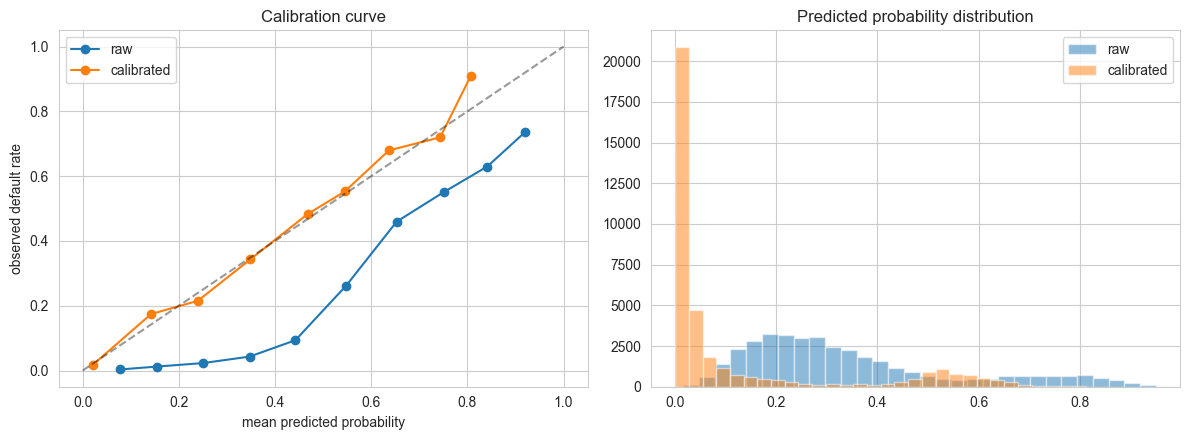

raw:        acc=0.874  f1_macro=0.766  f1_weighted=0.886  auc=0.894
calibrated: acc=0.900  f1_macro=0.766  f1_weighted=0.899  auc=0.923


In [34]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

base_for_calibration = results[best_model_name]["model"] if ("Tuned " + best_model_name) not in results else results["Tuned " + best_model_name]["model"]

calibrated = CalibratedClassifierCV(base_for_calibration, method="isotonic", cv=5)
calibrated.fit(X_train, y_train)
calib_probs = calibrated.predict_proba(X_val)[:, 1]
calib_preds = (calib_probs >= 0.5).astype(int)
calib_scores = get_scores(y_val, calib_preds, calib_probs)

results["Calibrated " + best_model_name] = {
    "model": calibrated, "X_val": X_val, "probs": calib_probs, "preds": calib_preds,
    **calib_scores,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, probs_to_plot in [("raw", results[best_model_name]["probs"]), ("calibrated", calib_probs)]:
    frac_pos, mean_pred = calibration_curve(y_val, probs_to_plot, n_bins=10)
    axes[0].plot(mean_pred, frac_pos, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("mean predicted probability")
axes[0].set_ylabel("observed default rate")
axes[0].set_title("Calibration curve")
axes[0].legend()

axes[1].hist(results[best_model_name]["probs"], bins=30, alpha=0.5, label="raw")
axes[1].hist(calib_probs, bins=30, alpha=0.5, label="calibrated")
axes[1].set_title("Predicted probability distribution")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"raw:        acc={results[best_model_name]['accuracy']:.3f}  f1_macro={results[best_model_name]['f1_macro']:.3f}  "
      f"f1_weighted={results[best_model_name]['f1_weighted']:.3f}  auc={results[best_model_name]['auc']:.3f}")
print(f"calibrated: acc={calib_scores['accuracy']:.3f}  f1_macro={calib_scores['f1_macro']:.3f}  "
      f"f1_weighted={calib_scores['f1_weighted']:.3f}  auc={calib_scores['auc']:.3f}")


## 8d. Threshold Tuning



In [35]:
def best_threshold_by_f1(y_true, y_prob):
    thresholds = np.linspace(0.01, 0.99, 99)
    f1s = [f1_score(y_true, (y_prob >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(f1s))
    return thresholds[best_idx], f1s[best_idx]

def best_threshold_by_accuracy(y_true, y_prob):
    thresholds = np.linspace(0.01, 0.99, 99)
    accs = [accuracy_score(y_true, (y_prob >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(accs))
    return thresholds[best_idx], accs[best_idx]

def threshold_closest_to_target_accuracy(y_true, y_prob, target=0.90):
    thresholds = np.linspace(0.01, 0.99, 99)
    accs = np.array([accuracy_score(y_true, (y_prob >= t).astype(int)) for t in thresholds])
    idx = int(np.argmin(np.abs(accs - target)))
    return thresholds[idx], accs[idx]


final_model_name = "Calibrated " + best_model_name
probs = results[final_model_name]["probs"]

t_f1, f1_val = best_threshold_by_f1(y_val.values, probs)
t_acc, acc_val = best_threshold_by_accuracy(y_val.values, probs)
t_target, acc_at_target = threshold_closest_to_target_accuracy(y_val.values, probs, target=0.90)

print(f"model: {final_model_name}\n")
for label, t in [("default 0.5", 0.5), ("F1-optimal", t_f1),
                  ("accuracy-optimal", t_acc), ("closest to 90% accuracy", t_target)]:
    preds_t = (probs >= t).astype(int)
    s = get_scores(y_val, preds_t, probs)
    print(f"{label:24s} (t={t:.2f}): acc={s['accuracy']:.3f}  f1={s['f1']:.3f}  "
          f"recall={s['recall']:.3f}  precision={s['precision']:.3f}  "
          f"f1_macro={s['f1_macro']:.3f}  f1_weighted={s['f1_weighted']:.3f}")

print(f"\nWorth noting: pushing accuracy up moves the threshold higher, which "
      f"means catching FEWER real defaulters (lower recall). Whether that's an "
      f"okay tradeoff is a business call, not a modeling one - F1-optimal is "
      f"usually the safer default unless you know for a fact accuracy is what's "
      f"being graded/judged.")

best_t = t_f1


model: Calibrated LightGBM (scale_pos_weight)

default 0.5              (t=0.50): acc=0.900  f1=0.589  recall=0.585  precision=0.593  f1_macro=0.766  f1_weighted=0.899
F1-optimal               (t=0.33): acc=0.896  f1=0.641  recall=0.755  precision=0.557  f1_macro=0.790  f1_weighted=0.903
accuracy-optimal         (t=0.47): acc=0.901  f1=0.623  recall=0.667  precision=0.585  f1_macro=0.783  f1_weighted=0.904
closest to 90% accuracy  (t=0.49): acc=0.900  f1=0.604  recall=0.621  precision=0.589  f1_macro=0.774  f1_weighted=0.901

Worth noting: pushing accuracy up moves the threshold higher, which means catching FEWER real defaulters (lower recall). Whether that's an okay tradeoff is a business call, not a modeling one - F1-optimal is usually the safer default unless you know for a fact accuracy is what's being graded/judged.


## 8e. Stacking Ensemble



In [36]:
stack_candidates = [n for n in ["XGBoost (scale_pos_weight)", "LightGBM (scale_pos_weight)",
                                 "CatBoost (scale_pos_weight)", "Random Forest (class_weight)"]
                    if n in results]

if len(stack_candidates) >= 2:
    estimators = [(name.split(" ")[0].lower(), results[name]["model"]) for name in stack_candidates]
    stack = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1,
    )
    stack.fit(X_train, y_train)
    stack_probs = stack.predict_proba(X_val)[:, 1]
    stack_preds = (stack_probs >= best_t).astype(int)
    stack_scores = get_scores(y_val, stack_preds, stack_probs)

    results["Stacked Ensemble"] = {
        "model": stack, "X_val": X_val, "probs": stack_probs, "preds": stack_preds,
        **stack_scores,
    }
    print(f"Stacked Ensemble: acc={stack_scores['accuracy']:.3f}  f1={stack_scores['f1']:.3f}  "
          f"f1_macro={stack_scores['f1_macro']:.3f}  f1_weighted={stack_scores['f1_weighted']:.3f}  "
          f"auc={stack_scores['auc']:.3f}")
else:
    print("not enough base models trained above to build a stack - skipping.")


Stacked Ensemble: acc=0.896  f1=0.623  f1_macro=0.781  f1_weighted=0.901  auc=0.903


## 8f. Summary 

In [37]:
summary_full = pd.DataFrame({
    name: {
        "Accuracy": r["accuracy"],
        "Precision": r["precision"], "Recall": r["recall"], "F1": r["f1"],
        "Precision (macro)": r["precision_macro"], "Recall (macro)": r["recall_macro"], "F1 (macro)": r["f1_macro"],
        "Precision (weighted)": r["precision_weighted"], "Recall (weighted)": r["recall_weighted"], "F1 (weighted)": r["f1_weighted"],
        "AUC": r["auc"], "H-measure": h_measure(y_val.values, r["probs"]),
    }
    for name, r in results.items()
}).T

summary_full.sort_values("H-measure", ascending=False)


,Accuracy,Precision,Recall,F1,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),AUC,H-measure
Calibrated LightGBM (scale_pos_weight),0.90,0.59,0.58,0.59,0.77,0.76,0.77,0.90,0.90,0.90,0.92,0.35
Tuned LightGBM (scale_pos_weight),0.89,0.53,0.78,0.63,0.75,0.84,0.78,0.91,0.89,0.90,0.92,0.34
Stacked Ensemble,0.90,0.56,0.69,0.62,0.76,0.81,0.78,0.91,0.90,0.90,0.90,0.33
LightGBM (scale_pos_weight),0.87,0.49,0.80,0.61,0.73,0.84,0.77,0.91,0.87,0.89,0.89,0.32
XGBoost (scale_pos_weight),0.84,0.42,0.79,0.54,0.69,0.82,0.72,0.90,0.84,0.86,0.87,0.28
Random Forest (class_weight),0.84,0.41,0.75,0.53,0.69,0.80,0.72,0.89,0.84,0.86,0.87,0.27
Random Forest (Undersample),0.81,0.37,0.78,0.50,0.67,0.80,0.69,0.89,0.81,0.83,0.87,0.27
Random Forest (SMOTETomek),0.73,0.29,0.81,0.42,0.63,0.76,0.62,0.88,0.73,0.77,0.83,0.19
Random Forest (SMOTE),0.73,0.28,0.80,0.42,0.62,0.76,0.62,0.88,0.73,0.77,0.83,0.18
CatBoost (scale_pos_weight),0.73,0.28,0.71,0.40,0.61,0.72,0.61,0.87,0.73,0.78,0.80,0.15


## 9. Feature Importance



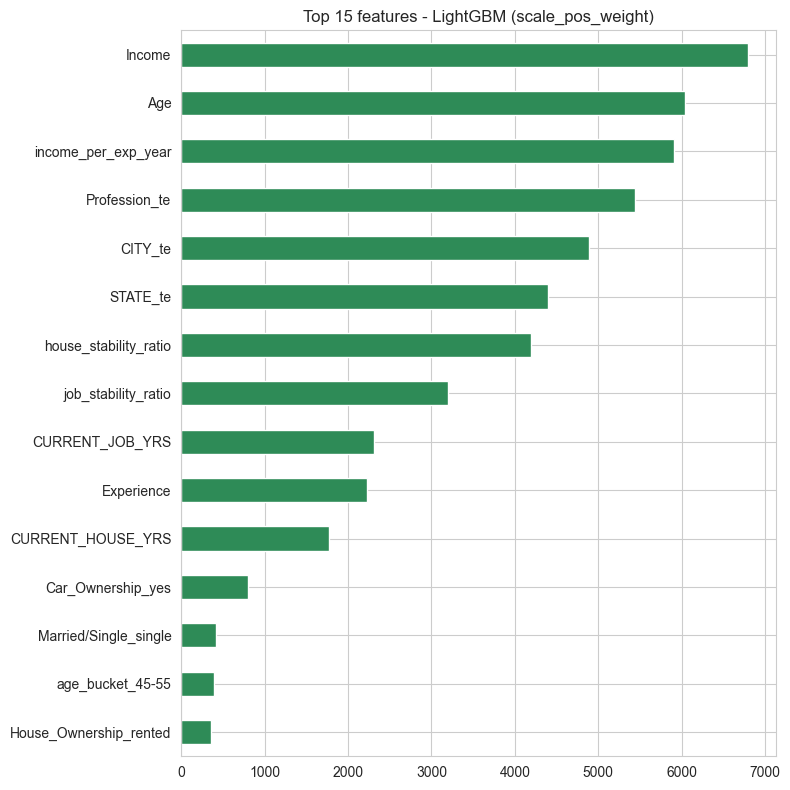

In [38]:
final_best_name = best_model_name  
raw_model_for_importance = results.get("Tuned " + best_model_name, results[best_model_name])["model"]


if hasattr(raw_model_for_importance, "feature_importances_"):
    importances = pd.Series(raw_model_for_importance.feature_importances_, index=feature_cols).sort_values(ascending=False)
    title_model = final_best_name
else:
    importances = pd.Series(results["Random Forest (class_weight)"]["model"].feature_importances_,
                             index=feature_cols).sort_values(ascending=False)
    title_model = "Random Forest (class_weight)"

plt.figure(figsize=(8, 8))
importances.head(15).sort_values().plot(kind="barh", color="seagreen")
plt.title(f"Top 15 features - {title_model}")
plt.tight_layout()
plt.show()


## 10. Final Predictions on Test Set


In [ ]:
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


final_deployed_model = results[final_model_name]["model"]

print("Best model      :", best_model_name)
print("Deployed model  :", final_model_name)
print("Threshold used  :", round(best_t, 2))


test_probs = final_deployed_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_t).astype(int)


print("\nEvaluation on Held-out Test Set")
print("-" * 40)
print("Accuracy :", accuracy_score(y_test, test_preds))
print("Precision:", precision_score(y_test, test_preds))
print("Recall   :", recall_score(y_test, test_preds))
print("F1-score :", f1_score(y_test, test_preds))
print("ROC-AUC  :", roc_auc_score(y_test, test_probs))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, test_preds))


submission = test_df[["ID"]].copy()

submission["Actual"] = y_test.values
submission["Prediction"] = test_preds
submission["Probability"] = test_probs

save_path = r"/Users/ghazal/Desktop/PADR/data/test_predictions.csv"  

os.makedirs(os.path.dirname(save_path), exist_ok=True)

submission.to_csv(save_path, index=False)

print(f"\nCSV saved successfully to:\n{save_path}")

submission.head(4)

Best model      : LightGBM (scale_pos_weight)
Deployed model  : Calibrated LightGBM (scale_pos_weight)
Threshold used  : 0.33

Evaluation on Held-out Test Set
----------------------------------------
Accuracy : 0.893968253968254
Precision: 0.5491941673062164
Recall   : 0.7696278769627877
F1-score : 0.6409888928699391
ROC-AUC  : 0.9210159676679448

Confusion Matrix
[[30214  2937]
 [ 1071  3578]]

CSV saved successfully to:
/Users/ghazal/Desktop/PADR/data/test_predictions.csv


,ID,Actual,Prediction,Probability
0,12602,0,0,0.00
1,122798,0,0,0.01
2,63612,0,0,0.01
3,40692,1,1,0.68
